In [2]:
import requests
import os

url = "https://www.thedatum.org/datasets/TSB-AD-U.zip"
zip_path = "/content/TSB-AD-U.zip"

headers = {
    "User-Agent": "Mozilla/5.0",
    "Accept": "application/zip,application/octet-stream,*/*"
}

response = requests.get(url, headers=headers, stream=True, timeout=60)

print("HTTP Status:", response.status_code)
print("Content-Type:", response.headers.get("Content-Type"))
print("Final URL:", response.url)

if response.status_code == 200:
    with open(zip_path, "wb") as f:
        for chunk in response.iter_content(chunk_size=1024 * 1024):
            if chunk:
                f.write(chunk)

    if open(zip_path, "rb").read(4) == b"PK\x03\x04":
        print("ZIP downloaded successfully!")
        print("File size:", round(os.path.getsize(zip_path) / (1024 * 1024), 2), "MB")
    else:
        print("The server returned a response, but it is not a valid ZIP file.")
else:
    print("Download still blocked. Response preview:")
    print(response.text[:300])

HTTP Status: 200
Content-Type: application/zip
Final URL: https://www.thedatum.org/datasets/TSB-AD-U.zip
ZIP downloaded successfully!
File size: 69.52 MB


In [3]:
import zipfile
import os

zip_path = "/content/TSB-AD-U.zip"
extract_path = "/content/TSB-AD-U"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

csv_files = []

for root, dirs, files in os.walk(extract_path):
    for file in files:
        if file.endswith(".csv"):
            csv_files.append(os.path.join(root, file))

print("Total CSV files:", len(csv_files))

print("\nFirst 10 CSV files:")
for file in csv_files[:10]:
    print(os.path.relpath(file, extract_path))

Dataset extracted successfully!
Total CSV files: 870

First 10 CSV files:
TSB-AD-U/188_SMD_id_11_Facility_tr_500_1st_392.csv
TSB-AD-U/747_YAHOO_id_197_Synthetic_tr_500_1st_893.csv
TSB-AD-U/005_NAB_id_5_Traffic_tr_594_1st_1645.csv
TSB-AD-U/551_YAHOO_id_1_Synthetic_tr_500_1st_893.csv
TSB-AD-U/703_YAHOO_id_153_Synthetic_tr_500_1st_623.csv
TSB-AD-U/482_UCR_id_180_Medical_tr_7500_1st_16000.csv
TSB-AD-U/220_LTDB_id_5_Medical_tr_500_1st_26.csv
TSB-AD-U/338_UCR_id_36_Facility_tr_9000_1st_12400.csv
TSB-AD-U/031_WSD_id_3_WebService_tr_826_1st_926.csv
TSB-AD-U/763_YAHOO_id_213_WebService_tr_500_1st_43.csv


In [4]:
import pandas as pd
import os

# Inspect the first 5 CSV files
for file_path in csv_files[:5]:

    df = pd.read_csv(file_path)

    print("\n" + "=" * 60)
    print("File:", os.path.basename(file_path))
    print("Shape:", df.shape)
    print("Columns:", list(df.columns))

    print("\nFirst 5 rows:")
    print(df.head())

    print("\nData types:")
    print(df.dtypes)

    # Check anomaly-label distribution
    if "Label" in df.columns:
        print("\nAnomaly label distribution:")
        print(df["Label"].value_counts())


File: 188_SMD_id_11_Facility_tr_500_1st_392.csv
Shape: (23703, 2)
Columns: ['Data', 'Label']

First 5 rows:
   Data  Label
0   0.0      0
1   0.0      0
2   0.0      0
3   0.0      0
4   0.0      0

Data types:
Data     float64
Label      int64
dtype: object

Anomaly label distribution:
Label
0    22886
1      817
Name: count, dtype: int64

File: 747_YAHOO_id_197_Synthetic_tr_500_1st_893.csv
Shape: (1421, 2)
Columns: ['Data', 'Label']

First 5 rows:
         Data  Label
0 -175.593664      0
1  164.793093      0
2  -45.758379      0
3  781.599526      0
4  495.365852      0

Data types:
Data     float64
Label      int64
dtype: object

Anomaly label distribution:
Label
0    1420
1       1
Name: count, dtype: int64

File: 005_NAB_id_5_Traffic_tr_594_1st_1645.csv
Shape: (2379, 2)
Columns: ['Data', 'Label']

First 5 rows:
   Data  Label
0  6.44      0
1  5.17      0
2  3.83      0
3  4.50      0
4  2.94      0

Data types:
Data     float64
Label      int64
dtype: object

Anomaly label dist

In [5]:
import pandas as pd

base_url = "https://raw.githubusercontent.com/TheDatumOrg/TSB-AD/main/Datasets/File_List/"

eval_url = base_url + "TSB-AD-U-Eva.csv"
tuning_url = base_url + "TSB-AD-U-Tuning.csv"

eval_list = pd.read_csv(eval_url)
tuning_list = pd.read_csv(tuning_url)

print("Evaluation files:", len(eval_list))
print("Tuning files:", len(tuning_list))

print("\nEvaluation list columns:")
print(eval_list.columns.tolist())

print("\nFirst 5 evaluation entries:")
print(eval_list.head())

Evaluation files: 350
Tuning files: 48

Evaluation list columns:
['file_name']

First 5 evaluation entries:
                                      file_name
0    001_NAB_id_1_Facility_tr_1007_1st_2014.csv
1  002_NAB_id_2_WebService_tr_1500_1st_4106.csv
2      005_NAB_id_5_Traffic_tr_594_1st_1645.csv
3     006_NAB_id_6_Traffic_tr_2579_1st_5839.csv
4   008_NAB_id_8_Synthetic_tr_1007_1st_2734.csv


In [6]:
import os
import pandas as pd

# Map each CSV filename to its full path
file_map = {
    os.path.basename(path): path
    for path in csv_files
}

results = []

for filename in eval_list["file_name"]:

    if filename not in file_map:
        continue

    df = pd.read_csv(file_map[filename])

    total = len(df)
    anomalies = int(df["Label"].sum())

    results.append({
        "file_name": filename,
        "total_points": total,
        "anomalies": anomalies,
        "normal_points": total - anomalies,
        "anomaly_percentage": round((anomalies / total) * 100, 2)
    })

# Create summary table
summary = pd.DataFrame(results)

print("Evaluation files found:", len(summary))

# Show files with at least 20 anomalies and manageable length
candidates = summary[
    (summary["total_points"] <= 10000) &
    (summary["anomalies"] >= 20)
].sort_values("total_points")

print("\nTop 15 candidate datasets:")
display(candidates.head(15))

Evaluation files found: 350

Top 15 candidate datasets:


,file_name,total_points,anomalies,normal_points,anomaly_percentage
6,010_NAB_id_10_WebService_tr_500_1st_271.csv,1000,148,852,14.80
157,283_NEK_id_7_WebService_tr_500_1st_777.csv,1073,120,953,11.18
158,284_NEK_id_8_WebService_tr_500_1st_976.csv,1073,89,984,8.29
159,285_NEK_id_9_WebService_tr_500_1st_780.csv,1073,108,965,10.07
152,277_NEK_id_1_WebService_tr_500_1st_17.csv,1073,88,985,8.20
153,278_NEK_id_2_WebService_tr_500_1st_64.csv,1073,65,1008,6.06
154,279_NEK_id_3_WebService_tr_500_1st_974.csv,1073,91,982,8.48
155,281_NEK_id_5_WebService_tr_500_1st_974.csv,1073,88,985,8.20
156,282_NEK_id_6_WebService_tr_500_1st_64.csv,1073,63,1010,5.87
284,734_YAHOO_id_184_WebService_tr_500_1st_768.csv,1424,227,1197,15.94


Dataset: 010_NAB_id_10_WebService_tr_500_1st_271.csv
Shape: (1000, 2)

Statistical summary:
count    1000.000000
mean        0.134848
std         0.083859
min         0.038899
25%         0.093459
50%         0.112189
75%         0.150154
max         1.034000
Name: Data, dtype: float64

Label distribution:
Label
0    852
1    148
Name: count, dtype: int64


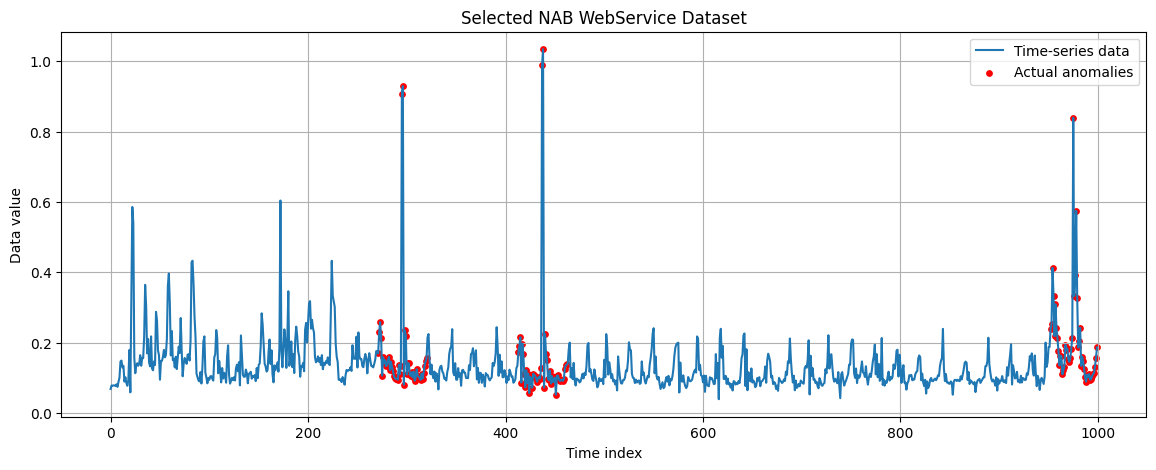

In [7]:
import matplotlib.pyplot as plt
import pandas as pd
import os

filename = "010_NAB_id_10_WebService_tr_500_1st_271.csv"
file_path = file_map[filename]

df = pd.read_csv(file_path)

print("Dataset:", filename)
print("Shape:", df.shape)
print("\nStatistical summary:")
print(df["Data"].describe())

print("\nLabel distribution:")
print(df["Label"].value_counts())

# Plot time-series values and anomaly labels
plt.figure(figsize=(14, 5))

plt.plot(df["Data"], label="Time-series data")
anomaly_indices = df.index[df["Label"] == 1]

plt.scatter(
    anomaly_indices,
    df.loc[anomaly_indices, "Data"],
    color="red",
    label="Actual anomalies",
    s=15
)

plt.title("Selected NAB WebService Dataset")
plt.xlabel("Time index")
plt.ylabel("Data value")
plt.legend()
plt.grid()
plt.show()

Missing values:
Data     0
Label    0
dtype: int64

Infinite values:
0

Duplicate data values: 0

Number of anomaly groups: 3
First 10 anomaly groups: [(271, 320), (413, 462), (952, 999)]


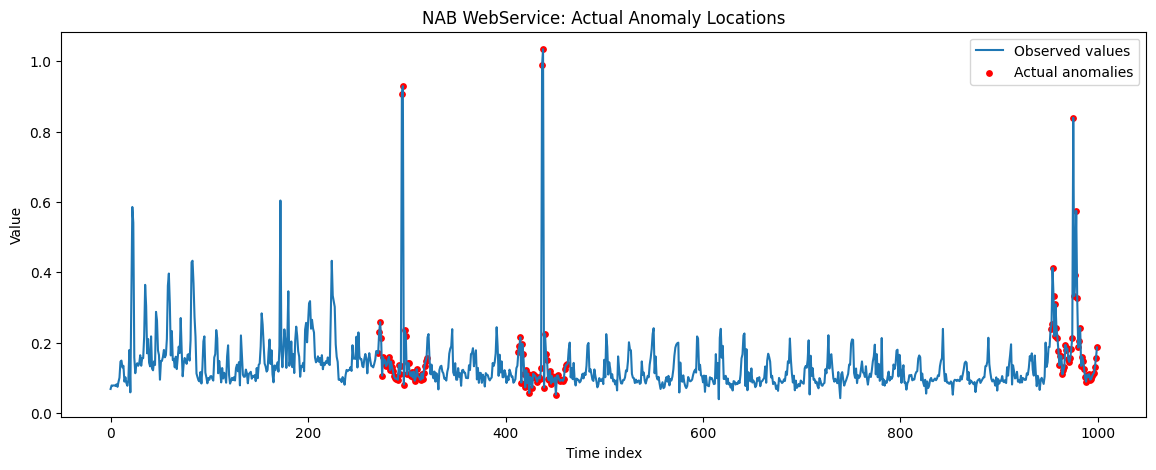

In [8]:
import numpy as np
import matplotlib.pyplot as plt

print("Missing values:")
print(df.isnull().sum())

print("\nInfinite values:")
print(np.isinf(df["Data"]).sum())

print("\nDuplicate data values:", df["Data"].duplicated().sum())

# Find consecutive anomaly groups
labels = df["Label"].values
groups = []
start = None

for i in range(len(labels)):
    if labels[i] == 1 and start is None:
        start = i
    elif labels[i] == 0 and start is not None:
        groups.append((start, i - 1))
        start = None

if start is not None:
    groups.append((start, len(labels) - 1))

print("\nNumber of anomaly groups:", len(groups))
print("First 10 anomaly groups:", groups[:10])

# Visualize the series
plt.figure(figsize=(14, 5))
plt.plot(df["Data"].values, label="Observed values")
plt.scatter(
    np.where(labels == 1)[0],
    df.loc[df["Label"] == 1, "Data"],
    color="red",
    s=15,
    label="Actual anomalies"
)
plt.title("NAB WebService: Actual Anomaly Locations")
plt.xlabel("Time index")
plt.ylabel("Value")
plt.legend()
plt.show()

In [9]:
import os
import json

project_path = "/content/ATR_Anomaly_Project"
os.makedirs(project_path, exist_ok=True)

# Save selected dataset
df.to_csv(
    os.path.join(project_path, "selected_dataset.csv"),
    index=False
)

# Save experiment information
experiment = {
    "dataset": filename,
    "dataset_source": "TSB-AD-U",
    "official_split": "Evaluation",
    "total_observations": 1000,
    "normal_observations": 852,
    "anomaly_observations": 148,
    "anomaly_groups": [
        [271, 320],
        [413, 462],
        [952, 999]
    ],
    "models": [
        "Isolation Forest",
        "Rolling Statistical Detector",
        "Chronos"
    ],
    "metrics": [
        "Precision",
        "Recall",
        "F1",
        "PR-AUC"
    ],
    "random_seed": 42
}

with open(
    os.path.join(project_path, "experiment.json"),
    "w"
) as f:
    json.dump(experiment, f, indent=4)

print("Experiment metadata saved!")
print("Project directory:", project_path)
print("Files:", os.listdir(project_path))

Experiment metadata saved!
Project directory: /content/ATR_Anomaly_Project
Files: ['selected_dataset.csv', 'experiment.json']


In [10]:
from sklearn.ensemble import IsolationForest
import numpy as np

# Prepare input
X = df[["Data"]].values

# Initialize Isolation Forest
model = IsolationForest(
    n_estimators=100,
    contamination=0.148,
    random_state=42
)

# Train model
model.fit(X)

# Predict anomalies
predictions = model.predict(X)

# Convert predictions:
# -1 = anomaly
#  1 = normal
y_pred = np.where(predictions == -1, 1, 0)

# Get anomaly scores
scores = -model.score_samples(X)

print("Isolation Forest completed!")
print("Total predicted anomalies:", np.sum(y_pred))
print("Total actual anomalies:", np.sum(df["Label"].values))
print("Anomaly score shape:", scores.shape)

Isolation Forest completed!
Total predicted anomalies: 148
Total actual anomalies: 148
Anomaly score shape: (1000,)


In [11]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

y_true = df["Label"].values

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(y_true, y_pred))

# Evaluation metrics
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

pr_auc = average_precision_score(y_true, scores)

print("Isolation Forest Results")
print("------------------------")
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))
print("PR-AUC:", round(pr_auc, 4))

Confusion Matrix:
[[737 115]
 [115  33]]

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.87      0.87       852
           1       0.22      0.22      0.22       148

    accuracy                           0.77      1000
   macro avg       0.54      0.54      0.54      1000
weighted avg       0.77      0.77      0.77      1000

Isolation Forest Results
------------------------
Precision: 0.223
Recall: 0.223
F1 Score: 0.223
PR-AUC: 0.2266


In [12]:
from sklearn.ensemble import IsolationForest
import numpy as np
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix
)

X = df[["Data"]].values
y_true = df["Label"].values

model = IsolationForest(
    n_estimators=100,
    contamination="auto",
    random_state=42
)

model.fit(X)

# Predictions: -1 = anomaly, 1 = normal
predictions = model.predict(X)
y_pred = np.where(predictions == -1, 1, 0)

# Higher score means more anomalous
scores = -model.score_samples(X)

print("Predicted anomalies:", np.sum(y_pred))
print("Actual anomalies:", np.sum(y_true))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nPrecision:", round(precision_score(y_true, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_true, y_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_true, y_pred, zero_division=0), 4))
print("PR-AUC:", round(average_precision_score(y_true, scores), 4))

Predicted anomalies: 151
Actual anomalies: 148

Confusion Matrix:
[[734 118]
 [115  33]]

Precision: 0.2185
Recall: 0.223
F1 Score: 0.2207
PR-AUC: 0.2266


In [13]:
train_size = 500

train_df = df.iloc[:train_size].copy()
test_df = df.iloc[train_size:].copy()

print("Training observations:", len(train_df))
print("Testing observations:", len(test_df))

print("\nTraining label distribution:")
print(train_df["Label"].value_counts())

print("\nTesting label distribution:")
print(test_df["Label"].value_counts())

print("\nTraining anomaly percentage:",
      round(train_df["Label"].mean() * 100, 2), "%")

print("Testing anomaly percentage:",
      round(test_df["Label"].mean() * 100, 2), "%")

Training observations: 500
Testing observations: 500

Training label distribution:
Label
0    400
1    100
Name: count, dtype: int64

Testing label distribution:
Label
0    452
1     48
Name: count, dtype: int64

Training anomaly percentage: 20.0 %
Testing anomaly percentage: 9.6 %


In [14]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)
import numpy as np

# Prepare training and testing data
X_train = train_df[["Data"]].values
X_test = test_df[["Data"]].values

y_test = test_df["Label"].values

# Train only on the first 500 observations
model = IsolationForest(
    n_estimators=100,
    contamination="auto",
    random_state=42
)

model.fit(X_train)

# Predict only on the remaining 500 observations
predictions = model.predict(X_test)

# Convert -1 (anomaly) and 1 (normal) into 1 and 0
y_pred = np.where(predictions == -1, 1, 0)

# Calculate anomaly scores
scores = -model.score_samples(X_test)

# Evaluate
print("Predicted anomalies:", np.sum(y_pred))
print("Actual anomalies:", np.sum(y_test))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nPrecision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("PR-AUC:", round(average_precision_score(y_test, scores), 4))

Predicted anomalies: 43
Actual anomalies: 48

Confusion Matrix:
[[421  31]
 [ 36  12]]

Precision: 0.2791
Recall: 0.25
F1 Score: 0.2637
PR-AUC: 0.2325


In [15]:
import pandas as pd
import os

results_path = os.path.join(project_path, "baseline_results.csv")

baseline_result = pd.DataFrame([{
    "Model": "Isolation Forest",
    "Train_Size": len(X_train),
    "Test_Size": len(X_test),
    "Precision": 0.2791,
    "Recall": 0.2500,
    "F1_Score": 0.2637,
    "PR_AUC": 0.2325
}])

baseline_result.to_csv(results_path, index=False)

print("Baseline result saved!")
print(pd.read_csv(results_path))

Baseline result saved!
              Model  Train_Size  Test_Size  Precision  Recall  F1_Score  \
0  Isolation Forest         500        500     0.2791    0.25    0.2637   

   PR_AUC  
0  0.2325  


In [16]:
import numpy as np
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix
)

# Calculate statistics using training data only
mean = np.mean(X_train)
std = np.std(X_train)

# Calculate anomaly scores on test data
z_scores = np.abs((X_test.flatten() - mean) / std)

# Fixed threshold
threshold = 3

# Predict anomalies
y_pred_z = (z_scores > threshold).astype(int)

# Evaluate
print("Z-score threshold:", threshold)
print("Predicted anomalies:", np.sum(y_pred_z))
print("Actual anomalies:", np.sum(y_test))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_z))

print("\nPrecision:", round(precision_score(y_test, y_pred_z, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred_z, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, y_pred_z, zero_division=0), 4))
print("PR-AUC:", round(average_precision_score(y_test, z_scores), 4))

Z-score threshold: 3
Predicted anomalies: 2
Actual anomalies: 48

Confusion Matrix:
[[452   0]
 [ 46   2]]

Precision: 1.0
Recall: 0.0417
F1 Score: 0.08
PR-AUC: 0.2864


In [17]:
import pandas as pd
import os
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

results = [
    {
        "Model": "Isolation Forest",
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1_Score": f1_score(y_test, y_pred),
        "PR_AUC": average_precision_score(y_test, scores)
    },
    {
        "Model": "Z-Score",
        "Precision": precision_score(y_test, y_pred_z),
        "Recall": recall_score(y_test, y_pred_z),
        "F1_Score": f1_score(y_test, y_pred_z),
        "PR_AUC": average_precision_score(y_test, z_scores)
    }
]

results_df = pd.DataFrame(results)

results_path = os.path.join(project_path, "baseline_results.csv")
results_df.to_csv(results_path, index=False)

print("Updated baseline results:")
display(results_df)
print("\nSaved to:", results_path)

Updated baseline results:


,Model,Precision,Recall,F1_Score,PR_AUC
0,Isolation Forest,0.27907,0.250000,0.263736,0.232504
1,Z-Score,1.00000,0.041667,0.080000,0.286447



Saved to: /content/ATR_Anomaly_Project/baseline_results.csv


In [18]:
import torch
import sys

print("Python version:", sys.version)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
PyTorch version: 2.11.0+cpu
CUDA available: False
Running on CPU


In [19]:
!pip install -q chronos-forecasting

In [20]:
import torch
from chronos import ChronosPipeline

pipeline = ChronosPipeline.from_pretrained(
    "amazon/chronos-t5-small",
    device_map="cpu",
    torch_dtype=torch.float32
)

print("Chronos-T5-Small loaded successfully!")

config.json:   0%|          | 0.00/1.11k [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B /  185MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/142 [00:00<?, ?B/s]

Chronos-T5-Small loaded successfully!


In [21]:
import numpy as np
import torch

all_values = df["Data"].to_numpy(dtype=np.float32)

train_size = 500
context_length = 128
test_values = all_values[train_size:]

# Build past-only contexts for every test observation
contexts = []

for i in range(len(test_values)):
    start = train_size + i - context_length
    end = train_size + i
    contexts.append(all_values[start:end])

contexts = np.array(contexts, dtype=np.float32)

# Generate forecasts in batches
all_forecasts = []

for i in range(0, len(contexts), 16):
    batch = torch.tensor(contexts[i:i+16])

    forecasts = pipeline.predict(
        batch,
        prediction_length=1,
        num_samples=20
    )

    all_forecasts.append(forecasts.cpu().numpy())

all_forecasts = np.concatenate(all_forecasts, axis=0)

# Median forecast and absolute prediction error
predicted_values = np.median(all_forecasts[:, :, 0], axis=1)
chronos_scores = np.abs(test_values - predicted_values)

print("Test observations:", len(test_values))
print("Forecasts generated:", len(predicted_values))
print("Anomaly scores generated:", len(chronos_scores))
print("\nFirst 5 actual values:", test_values[:5])
print("First 5 forecast values:", predicted_values[:5])
print("First 5 anomaly scores:", chronos_scores[:5])

Test observations: 500
Forecasts generated: 500
Anomaly scores generated: 500

First 5 actual values: [0.15104982 0.10144411 0.2239322  0.18785937 0.1090036 ]
First 5 forecast values: [0.09602967 0.11446019 0.09766775 0.10210378 0.17474174]
First 5 anomaly scores: [0.05502015 0.01301607 0.12626445 0.08575559 0.06573814]


In [22]:
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    average_precision_score, confusion_matrix
)

# Generate one-step forecasts within the training period
train_values = all_values[:train_size]
train_contexts = []

for i in range(context_length, train_size):
    train_contexts.append(train_values[i-context_length:i])

train_contexts = np.array(train_contexts, dtype=np.float32)

train_forecasts = []

for i in range(0, len(train_contexts), 16):
    batch = torch.tensor(train_contexts[i:i+16])

    forecasts = pipeline.predict(
        batch,
        prediction_length=1,
        num_samples=20
    )

    train_forecasts.append(forecasts.cpu().numpy())

train_forecasts = np.concatenate(train_forecasts, axis=0)

train_predicted = np.median(train_forecasts[:, :, 0], axis=1)
train_actual = train_values[context_length:]

train_errors = np.abs(train_actual - train_predicted)

# Calibrate threshold using training errors only
threshold = np.quantile(train_errors, 0.95)

# Classify test observations
y_pred_chronos = (chronos_scores > threshold).astype(int)

# Evaluate against test labels
y_test = test_df["Label"].to_numpy()

print("Training calibration observations:", len(train_errors))
print("Chronos threshold:", threshold)
print("Predicted anomalies:", y_pred_chronos.sum())
print("Actual anomalies:", y_test.sum())

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_chronos))

print("\nChronos Results:")
print("Precision:", precision_score(y_test, y_pred_chronos, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_chronos, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred_chronos, zero_division=0))
print("PR-AUC:", average_precision_score(y_test, chronos_scores))

Training calibration observations: 372
Chronos threshold: 0.095793605
Predicted anomalies: 12
Actual anomalies: 48

Confusion Matrix:
[[446   6]
 [ 42   6]]

Chronos Results:
Precision: 0.5
Recall: 0.125
F1 Score: 0.2
PR-AUC: 0.283510697534112


In [23]:
import pandas as pd
import os

results = [
    {
        "Model": "Isolation Forest",
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1_Score": f1_score(y_test, y_pred),
        "PR_AUC": average_precision_score(y_test, scores)
    },
    {
        "Model": "Z-Score",
        "Precision": precision_score(y_test, y_pred_z),
        "Recall": recall_score(y_test, y_pred_z),
        "F1_Score": f1_score(y_test, y_pred_z),
        "PR_AUC": average_precision_score(y_test, z_scores)
    },
    {
        "Model": "Chronos-T5-Small",
        "Precision": precision_score(y_test, y_pred_chronos),
        "Recall": recall_score(y_test, y_pred_chronos),
        "F1_Score": f1_score(y_test, y_pred_chronos),
        "PR_AUC": average_precision_score(y_test, chronos_scores)
    }
]

results_df = pd.DataFrame(results)

results_path = os.path.join(project_path, "final_results.csv")
results_df.to_csv(results_path, index=False)

print("Final results saved successfully!")
print(results_df.round(4).to_string(index=False))
print("\nSaved at:", results_path)

Final results saved successfully!
           Model  Precision  Recall  F1_Score  PR_AUC
Isolation Forest     0.2791  0.2500    0.2637  0.2325
         Z-Score     1.0000  0.0417    0.0800  0.2864
Chronos-T5-Small     0.5000  0.1250    0.2000  0.2835

Saved at: /content/ATR_Anomaly_Project/final_results.csv


In [24]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

percentiles = [90, 95, 97.5, 99]
sensitivity_results = []

for p in percentiles:
    threshold_value = np.percentile(train_errors, p)

    predictions = (chronos_scores > threshold_value).astype(int)

    sensitivity_results.append({
        "Training Percentile": p,
        "Threshold": threshold_value,
        "Predicted Anomalies": predictions.sum(),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1_Score": f1_score(y_test, predictions, zero_division=0)
    })

sensitivity_df = pd.DataFrame(sensitivity_results)

sensitivity_path = os.path.join(
    project_path, "chronos_threshold_sensitivity.csv"
)

sensitivity_df.to_csv(sensitivity_path, index=False)

print(sensitivity_df.round(4).to_string(index=False))
print("\nSaved at:", sensitivity_path)

 Training Percentile  Threshold  Predicted Anomalies  Precision  Recall  F1_Score
                90.0     0.0710                   34     0.2941  0.2083    0.2439
                95.0     0.0958                   12     0.5000  0.1250    0.2000
                97.5     0.1405                    4     1.0000  0.0833    0.1538
                99.0     0.7911                    1     1.0000  0.0208    0.0408

Saved at: /content/ATR_Anomaly_Project/chronos_threshold_sensitivity.csv


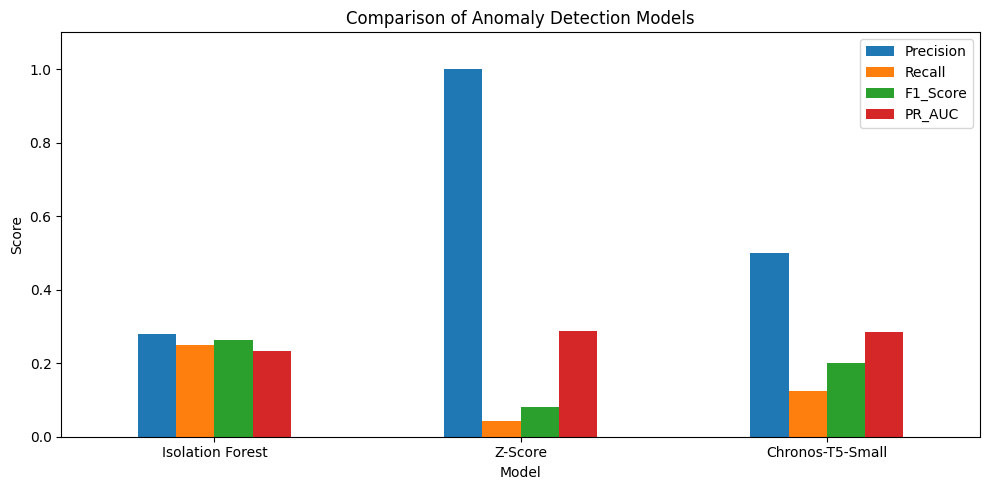

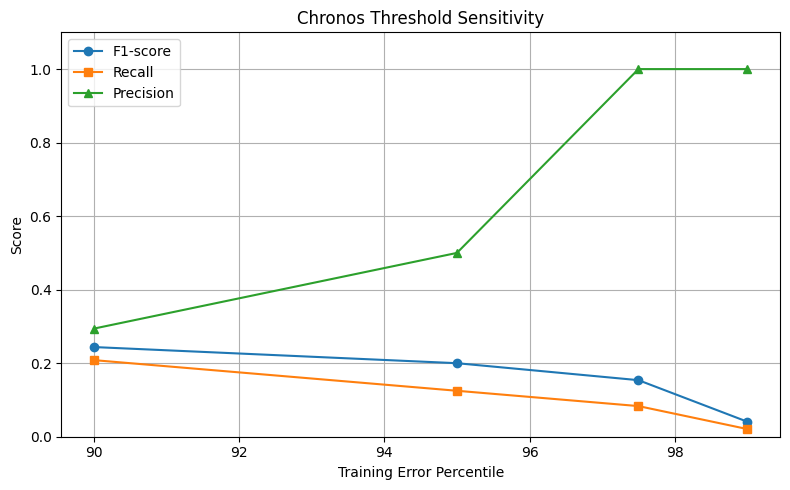

Both graphs saved successfully!


In [25]:
import matplotlib.pyplot as plt
import os

# Graph 1: Compare model performance
metrics = ["Precision", "Recall", "F1_Score", "PR_AUC"]

results_df.plot(
    x="Model",
    y=metrics,
    kind="bar",
    figsize=(10, 5)
)

plt.title("Comparison of Anomaly Detection Models")
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    os.path.join(project_path, "model_comparison.png"),
    dpi=300
)

plt.show()


# Graph 2: Chronos threshold sensitivity
plt.figure(figsize=(8, 5))

plt.plot(
    sensitivity_df["Training Percentile"],
    sensitivity_df["F1_Score"],
    marker="o",
    label="F1-score"
)

plt.plot(
    sensitivity_df["Training Percentile"],
    sensitivity_df["Recall"],
    marker="s",
    label="Recall"
)

plt.plot(
    sensitivity_df["Training Percentile"],
    sensitivity_df["Precision"],
    marker="^",
    label="Precision"
)

plt.xlabel("Training Error Percentile")
plt.ylabel("Score")
plt.title("Chronos Threshold Sensitivity")
plt.ylim(0, 1.1)
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    os.path.join(project_path, "chronos_sensitivity.png"),
    dpi=300
)

plt.show()

print("Both graphs saved successfully!")

In [26]:
summary = """
RESEARCH PROJECT
An Empirical Evaluation of Pretrained Time-Series Foundation
Models and Traditional Machine Learning Models for
Time-Series Anomaly Detection

DATASET
Source: TSB-AD-U
Selected file: 010_NAB_id_10_WebService_tr_500_1st_271.csv
Total observations: 1000
Training observations: 500
Testing observations: 500
Training anomalies: 100
Testing anomalies: 48

MODELS
1. Isolation Forest
2. Z-Score
3. Chronos-T5-Small

TEST RESULTS
Isolation Forest:
Precision = 0.2791
Recall = 0.2500
F1-score = 0.2637
PR-AUC = 0.2325

Z-Score:
Precision = 1.0000
Recall = 0.0417
F1-score = 0.0800
PR-AUC = 0.2864

Chronos-T5-Small:
Precision = 0.5000
Recall = 0.1250
F1-score = 0.2000
PR-AUC = 0.2835

THRESHOLD SENSITIVITY
Chronos was evaluated at the 90th, 95th, 97.5th,
and 99th percentiles of training forecasting errors.
The 90th percentile produced the highest F1-score
among the tested thresholds (0.2439).

EXPERIMENTAL LIMITATION
This is a single-time-series pilot experiment.
Results should not be generalized to all time-series
datasets or all foundation models.
"""

summary_path = os.path.join(project_path, "research_summary.txt")

with open(summary_path, "w") as file:
    file.write(summary)

print("Research summary saved successfully!")
print("Location:", summary_path)

Research summary saved successfully!
Location: /content/ATR_Anomaly_Project/research_summary.txt


In [27]:
import pandas as pd
import os
import sys
import torch

predictions_df = pd.DataFrame({
    "Actual_Value": test_values,
    "Actual_Label": y_test,

    "IF_Anomaly_Score": scores,
    "IF_Prediction": y_pred,

    "ZScore": z_scores,
    "ZScore_Prediction": y_pred_z,

    "Chronos_Forecast": predicted_values,
    "Chronos_Anomaly_Score": chronos_scores,
    "Chronos_Prediction": y_pred_chronos
})

predictions_path = os.path.join(
    project_path, "test_predictions.csv"
)

predictions_df.to_csv(predictions_path, index=False)

# Save experiment environment
environment = {
    "Python": sys.version,
    "PyTorch": torch.__version__,
    "Device": "CPU",
    "Chronos_Model": "amazon/chronos-t5-small",
    "Random_Seed": 42,
    "Training_Size": 500,
    "Testing_Size": 500,
    "Chronos_Context_Length": 128,
    "Chronos_Num_Samples": 20,
    "Chronos_Threshold_Percentile": 95
}

environment_df = pd.DataFrame(
    list(environment.items()),
    columns=["Setting", "Value"]
)

environment_path = os.path.join(
    project_path, "experiment_environment.csv"
)

environment_df.to_csv(environment_path, index=False)

print("Individual predictions saved!")
print("Environment details saved!")
print("\nPrediction file shape:", predictions_df.shape)
print("\nProject files:")
print(os.listdir(project_path))

Individual predictions saved!
Environment details saved!

Prediction file shape: (500, 9)

Project files:
['chronos_sensitivity.png', 'model_comparison.png', 'test_predictions.csv', 'chronos_threshold_sensitivity.csv', 'baseline_results.csv', 'experiment_environment.csv', 'research_summary.txt', 'selected_dataset.csv', 'experiment.json', 'final_results.csv']


In [28]:
import pandas as pd
import os

for filename in ["baseline_results.csv", "final_results.csv"]:
    path = os.path.join(project_path, filename)

    data = pd.read_csv(path)
    data.rename(columns={"PR_AUC": "Average_Precision_AP"}, inplace=True)
    data.to_csv(path, index=False)

# Correct the metric name in the summary
summary_path = os.path.join(project_path, "research_summary.txt")

with open(summary_path, "r") as file:
    summary = file.read()

summary = summary.replace("PR-AUC", "Average Precision (AP)")

with open(summary_path, "w") as file:
    file.write(summary)

print("Metric labels corrected!")
print("\nUpdated final results:")
print(pd.read_csv(
    os.path.join(project_path, "final_results.csv")
).round(4).to_string(index=False))

Metric labels corrected!

Updated final results:
           Model  Precision  Recall  F1_Score  Average_Precision_AP
Isolation Forest     0.2791  0.2500    0.2637                0.2325
         Z-Score     1.0000  0.0417    0.0800                0.2864
Chronos-T5-Small     0.5000  0.1250    0.2000                0.2835


In [30]:
import os
import shutil
from google.colab import files

project_path = "/content/ATR_Anomaly_Project"

# Check project folder
if os.path.exists(project_path):

    # Create ZIP file
    zip_path = shutil.make_archive(
        "/content/ATR_Anomaly_Project",
        "zip",
        project_path
    )

    # Verify ZIP exists
    if os.path.exists(zip_path):
        print("ZIP created successfully!")
        print("File size:", round(os.path.getsize(zip_path) / (1024 * 1024), 2), "MB")

        # Download
        files.download(zip_path)

    else:
        print("ZIP creation failed.")

else:
    print("Project folder not found:", project_path)

ZIP created successfully!
File size: 0.2 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>